# Iterative Solvers for a Mixed Darcy Saddle-Point System

## 1. Understanding MINRES and GMRES

In my first notebook, I implemented a mixed Darcy problem and solved the saddle-point system using SciPy's direct solver.

Now I want to study iterative solvers for the same problem.

The linear system is:

$$
Gz=b
$$

I will study two iterative methods:

- MINRES, which is suitable for symmetric indefinite systems.
- GMRES, which can solve general nonsymmetric systems.

In this first step, I will check whether both solvers are available in SciPy.

I will also use a small example matrix to understand what a symmetric indefinite matrix means.


In [67]:
# Step 1: Understanding MINRES and GMRES

import numpy as np
import scipy

from scipy.sparse.linalg import minres, gmres

# Small example of a saddle-point matrix
G_demo = np.array([
    [2.0, 1.0],
    [1.0, 0.0]
])

# Check symmetry
is_symmetric = np.allclose(G_demo, G_demo.T)

# Calculate eigenvalues
eigenvalues = np.linalg.eigvalsh(G_demo)

# Check if the matrix is indefinite
is_indefinite = (
    np.any(eigenvalues > 0)
    and np.any(eigenvalues < 0)
)

# Display results
print("SciPy version:", scipy.__version__)
print("MINRES available:", callable(minres))
print("GMRES available:", callable(gmres))
print("Matrix is symmetric:", is_symmetric)
print("Eigenvalues:", eigenvalues)
print("Matrix is indefinite:", is_indefinite)


SciPy version: 1.16.3
MINRES available: True
GMRES available: True
Matrix is symmetric: True
Eigenvalues: [-0.41421356  2.41421356]
Matrix is indefinite: True


### Result

I checked that MINRES and GMRES are available in SciPy version 1.16.3.

I also tested a small symmetric matrix. Its eigenvalues were approximately -0.4142 and 2.4142.

Since the matrix has both negative and positive eigenvalues, it is indefinite.

This example helped me understand the type of matrix that MINRES can handle. GMRES can also solve symmetric indefinite systems, as well as general nonsymmetric systems.

In the next step, I will prepare the mixed Darcy saddle-point system for testing these iterative solvers.

## 2. Preparing the Mixed Darcy System

In this step, I will prepare the same mixed Darcy system that I used in my first notebook.

I will use a 2D triangular mesh with RT0 elements for flux and P0 elements for pressure.

The linear system is:

$$
Gz=b
$$

The saddle-point matrix is:

$$
G=
\begin{bmatrix}
A & -D^T \\
-D & 0
\end{bmatrix}
$$

The right-hand side is:

$$
b=
\begin{bmatrix}
0 \\
-F
\end{bmatrix}
$$

I will assemble the matrix and right-hand side and check their sizes and symmetry.

I will use this system later to test MINRES and GMRES.


In [68]:
# Step 2: Prepare the mixed Darcy system

# Install the finite element library
%pip -q install scikit-fem

from skfem import MeshTri, Basis, ElementTriRT0, ElementTriP0
from skfem import BilinearForm, LinearForm, asm
from skfem.helpers import dot, div
from scipy.sparse import bmat

# Create a triangular mesh
mesh = MeshTri.init_tensor(
    np.linspace(0, 1, 5),
    np.linspace(0, 1, 5)
)

# Define flux and pressure spaces
flux_basis = Basis(mesh, ElementTriRT0(), intorder=2)
pressure_basis = Basis(mesh, ElementTriP0(), intorder=2)

# Flux mass matrix
@BilinearForm
def flux_form(q, v, w):
    return dot(q, v)

# Divergence matrix
@BilinearForm
def divergence_form(q, r, w):
    return div(q) * r

# Source term
@LinearForm
def source_form(r, w):
    x = w.x[0]
    y = w.x[1]
    f = 2 * np.pi**2 * np.sin(np.pi*x) * np.sin(np.pi*y)
    return f * r

# Assemble the matrices
A = asm(flux_form, flux_basis)
D = asm(divergence_form, flux_basis, pressure_basis)

# Create the saddle-point matrix
G = bmat([
    [A, -D.T],
    [-D, None]
], format="csr")

# Create the right-hand side
F = asm(source_form, pressure_basis)
b = np.concatenate((np.zeros(flux_basis.N), -F))

# Print the results
print("Number of triangles:", mesh.t.shape[1])
print("Flux degrees of freedom:", flux_basis.N)
print("Pressure degrees of freedom:", pressure_basis.N)
print("Matrix shape:", G.shape)
print("Right-hand side shape:", b.shape)
print("Matrix is symmetric:", np.allclose(G.toarray(), G.toarray().T))

Note: you may need to restart the kernel to use updated packages.
Number of triangles: 32
Flux degrees of freedom: 56
Pressure degrees of freedom: 32
Matrix shape: (88, 88)
Right-hand side shape: (88,)
Matrix is symmetric: True


### Result

I prepared the same mixed Darcy system that I used in my first notebook.

The mesh has 32 triangles. There are 56 flux degrees of freedom and 32 pressure degrees of freedom.

The full saddle-point matrix has a size of 88 × 88, and the right-hand-side vector has 88 entries.

I also checked that the matrix is symmetric.

These results match my first notebook. Now I can use this system to test MINRES and GMRES.

## 3. Solving the Mixed Darcy System Using MINRES

In this step, I will solve the mixed Darcy system using the MINRES iterative solver from SciPy.

The linear system is:

$$
Gz=b
$$

I will use the same matrix and right-hand side from Step 2.

I want to check whether MINRES converges and how many iterations it takes.

I will also calculate the residual:

$$
r=b-Gz
$$

The relative residual is:

$$
\frac{\|b-Gz\|_2}{\|b\|_2}
$$

This will help me check how accurately MINRES solves the linear system.


In [69]:
# Step 3: Solve the Darcy system using MINRES

from scipy.sparse.linalg import minres

# Store the number of iterations
iterations = []

def count_iteration(x):
    iterations.append(1)

# Solve the system using MINRES
z_minres, info = minres(
    G,
    b,
    rtol=1e-8,
    maxiter=500,
    callback=count_iteration
)

# Calculate the residual
residual = b - G @ z_minres

# Calculate the relative residual
residual_norm = np.linalg.norm(residual)
relative_residual = residual_norm / np.linalg.norm(b)

# Print the results
print("MINRES info:", info)
print("Number of iterations:", len(iterations))
print("All solution values are finite:", np.all(np.isfinite(z_minres)))
print("Residual norm:", residual_norm)
print("Relative residual:", relative_residual)

MINRES info: 0
Number of iterations: 24
All solution values are finite: True
Residual norm: 7.050516990977738e-14
Relative residual: 4.182249841474048e-14


### Result

I solved the mixed Darcy system using the MINRES iterative solver.

MINRES converged successfully in 24 iterations.

The residual norm was approximately 7.05 × 10⁻¹⁴, and the relative residual was approximately 4.18 × 10⁻¹⁴.

All the calculated solution values were finite.

These results show that MINRES solved the assembled linear system accurately for the current mesh.

I will compare this result with GMRES and the direct solver in the next steps.

## 4. Solving the Mixed Darcy System Using GMRES

In this step, I will solve the same mixed Darcy system using GMRES from SciPy.

The linear system is:

$$
Gz=b
$$

I already solved this system using MINRES. Now I want to check how GMRES performs on the same problem.

I will check the solver status, number of iterations, and relative residual.

The relative residual is:

$$
\frac{\|b-Gz\|_2}{\|b\|_2}
$$

I will use GMRES without a preconditioner for this first test.


In [70]:
# Step 4: Solve the Darcy system using GMRES

from scipy.sparse.linalg import gmres

# Store the number of iterations
gmres_iterations = []

def count_gmres_iteration(residual_value):
    gmres_iterations.append(1)

# Solve the system using GMRES
z_gmres, gmres_info = gmres(
    G,
    b,
    rtol=1e-8,
    atol=0.0,
    restart=50,
    maxiter=20,
    callback=count_gmres_iteration,
    callback_type="pr_norm"
)

# Calculate the residual
gmres_residual = b - G @ z_gmres

# Calculate the relative residual
gmres_residual_norm = np.linalg.norm(gmres_residual)
gmres_relative_residual = gmres_residual_norm / np.linalg.norm(b)

# Print the results
print("GMRES info:", gmres_info)
print("Number of iterations:", len(gmres_iterations))
print("All solution values are finite:", np.all(np.isfinite(z_gmres)))
print("Residual norm:", gmres_residual_norm)
print("Relative residual:", gmres_relative_residual)

GMRES info: 0
Number of iterations: 24
All solution values are finite: True
Residual norm: 4.24625170228828e-14
Relative residual: 2.5188061430785e-14


### Result

I solved the mixed Darcy system using GMRES without a preconditioner.

GMRES converged successfully in 24 iterations.

The residual norm was approximately 4.25 × 10⁻¹⁴, and the relative residual was approximately 2.52 × 10⁻¹⁴.

All the calculated solution values were finite.

For this mesh, both MINRES and GMRES converged in 24 iterations. GMRES gave a slightly smaller final residual, but I cannot decide which solver is faster from these results alone.

I will compare their solutions and numerical performance in the next steps.

## 5. Comparing MINRES, GMRES, and the Direct Solver

In this step, I will compare the solutions calculated by MINRES, GMRES, and SciPy's direct solver.

I will solve the same mixed Darcy system using `spsolve`.

Then I will calculate the difference between each iterative solution and the direct solver solution.

For MINRES, the relative solution difference is:

$$
\frac{\|z_{\mathrm{MINRES}}-z_{\mathrm{direct}}\|_2}
{\|z_{\mathrm{direct}}\|_2}
$$

I will use the same calculation for GMRES.

I will also compare the relative residuals of all three solvers.

This will help me check whether the iterative solutions agree with the direct solver solution.


In [71]:
# Step 5: Compare the three solvers

from scipy.sparse.linalg import spsolve

# Solve the same system using a direct solver
z_direct = spsolve(G, b)

# Calculate solution differences
minres_difference = np.linalg.norm(z_minres - z_direct)
gmres_difference = np.linalg.norm(z_gmres - z_direct)

# Calculate relative solution differences
direct_norm = np.linalg.norm(z_direct)

minres_relative_difference = minres_difference / direct_norm
gmres_relative_difference = gmres_difference / direct_norm

# Calculate relative residuals
b_norm = np.linalg.norm(b)

direct_residual = np.linalg.norm(b - G @ z_direct) / b_norm
minres_residual = np.linalg.norm(b - G @ z_minres) / b_norm
gmres_residual = np.linalg.norm(b - G @ z_gmres) / b_norm

# Print results
print("Direct solver relative residual:", direct_residual)
print("MINRES relative residual:", minres_residual)
print("GMRES relative residual:", gmres_residual)

print("------------------------------------------------------")

print("MINRES relative solution difference:", minres_relative_difference)
print("GMRES relative solution difference:", gmres_relative_difference)

Direct solver relative residual: 7.443571321860165e-16
MINRES relative residual: 4.182249841474048e-14
GMRES relative residual: 2.5188061430785e-14
------------------------------------------------------
MINRES relative solution difference: 7.28825140314729e-15
GMRES relative solution difference: 4.3793585727512255e-15


### Result

I compared the solutions from MINRES and GMRES with the direct solver solution.

The direct solver gave a relative residual of approximately 7.44 × 10⁻¹⁶.

The relative residuals for MINRES and GMRES were approximately 4.18 × 10⁻¹⁴ and 2.52 × 10⁻¹⁴.

I also calculated the relative differences between the iterative solutions and the direct solver solution.

The difference was approximately 7.29 × 10⁻¹⁵ for MINRES and 4.38 × 10⁻¹⁵ for GMRES.

These small differences show that both iterative solvers gave results very close to the direct solver solution.

I still need to compare their iteration counts and computation times on different mesh sizes to understand their performance.

## 6. Comparing Solver Iterations and Computation Times

In this step, I will compare the computation times of the direct solver, MINRES, and GMRES.

I already checked that all three solvers give very similar solutions for the current Darcy system.

Now I want to see how much time each solver takes.

I will use Python's `time.perf_counter()` to measure the execution time.

I will run each solver five times and calculate the average time in milliseconds.

I will also check the iteration counts for MINRES and GMRES.

Since my current matrix is small, I will treat these timings as an initial experiment rather than a final performance comparison.


In [72]:
# Step 6: Compare solver computation times

import time

# Lists to store times in milliseconds
direct_times = []
minres_times = []
gmres_times = []

# Run each solver 5 times
for i in range(5):

    # Direct solver
    start = time.perf_counter()
    z_direct = spsolve(G, b)
    direct_times.append((time.perf_counter() - start) * 1000)

    # MINRES
    iterations.clear()

    start = time.perf_counter()
    z_minres, minres_info = minres(
        G, b,
        rtol=1e-8,
        maxiter=500,
        callback=count_iteration
    )
    minres_times.append((time.perf_counter() - start) * 1000)

    # GMRES
    gmres_iterations.clear()

    start = time.perf_counter()
    z_gmres, gmres_info = gmres(
        G, b,
        rtol=1e-8,
        atol=0.0,
        restart=50,
        maxiter=20,
        callback=count_gmres_iteration,
        callback_type="pr_norm"
    )
    gmres_times.append((time.perf_counter() - start) * 1000)

# Calculate average times
direct_avg = np.mean(direct_times)
minres_avg = np.mean(minres_times)
gmres_avg = np.mean(gmres_times)

# Print the results
print("Direct solver average time (ms):", direct_avg)
print("MINRES average time (ms):", minres_avg)
print("GMRES average time (ms):", gmres_avg)

print("--------------------------------")

print("MINRES iterations:", len(iterations))
print("GMRES iterations:", len(gmres_iterations))

print("MINRES info:", minres_info)
print("GMRES info:", gmres_info)


Direct solver average time (ms): 0.37727700037066825
MINRES average time (ms): 1.7894978000185802
GMRES average time (ms): 6.519196200315491
--------------------------------
MINRES iterations: 24
GMRES iterations: 24
MINRES info: 0
GMRES info: 0


### Result

I compared the computation times of the direct solver, MINRES, and GMRES.

I ran each solver five times and calculated the average execution time.

The direct solver took approximately 0.38 ms, MINRES took 1.79 ms, and GMRES took 6.52 ms.

These times may change when I run the notebook again.

Both MINRES and GMRES converged in 24 iterations.

For this small system, the direct solver was the fastest in my timing experiment. MINRES was also faster than GMRES.

I noticed that MINRES and GMRES took the same number of iterations but had different execution times.

Since I tested only a small matrix, I cannot use these results to decide which method is better for larger problems.

I will need to test different mesh sizes to make a more useful comparison.

## 7. Comparing MINRES and GMRES on Different Mesh Sizes

In this step, I will test MINRES and GMRES on three different meshes.

I will use 32, 128, and 512 triangles.

For each mesh, I will assemble the same mixed Darcy problem and solve it using MINRES and GMRES.

I want to check:

- The number of unknowns.
- The number of iterations for each solver.
- Whether the solvers converge.
- The final relative residuals.

I will use the same relative tolerance for both solvers.

This will help me understand how the iterative methods behave when the problem size increases.

I am not using any preconditioner in this step.


In [73]:
# Step 7: Test MINRES and GMRES on different meshes

mesh_sizes = [4, 8, 16]

for n in mesh_sizes:

    # Create a new mesh
    mesh_new = MeshTri.init_tensor(
        np.linspace(0, 1, n + 1),
        np.linspace(0, 1, n + 1)
    )

    # Define flux and pressure spaces
    qb = Basis(mesh_new, ElementTriRT0(), intorder=2)
    pb = Basis(mesh_new, ElementTriP0(), intorder=2)

    # Assemble the matrices
    A_new = asm(flux_form, qb)
    D_new = asm(divergence_form, qb, pb)

    G_new = bmat([
        [A_new, -D_new.T],
        [-D_new, None]
    ], format="csr")

    # Assemble the right-hand side
    F_new = asm(source_form, pb)
    b_new = np.concatenate((np.zeros(qb.N), -F_new))

    # Count MINRES iterations
    minres_steps = []

    def track_minres(x):
        minres_steps.append(1)

    # Run MINRES
    z_m, info_m = minres(
        G_new, b_new,
        rtol=1e-8,
        maxiter=3000,
        callback=track_minres
    )

    # Count GMRES iterations
    gmres_steps = []

    def track_gmres(r):
        gmres_steps.append(1)

    # Run GMRES
    z_g, info_g = gmres(
        G_new, b_new,
        rtol=1e-8,
        atol=0.0,
        restart=50,
        maxiter=60,
        callback=track_gmres,
        callback_type="pr_norm"
    )

    # Calculate relative residuals
    b_norm = np.linalg.norm(b_new)

    residual_m = np.linalg.norm(b_new - G_new @ z_m) / b_norm
    residual_g = np.linalg.norm(b_new - G_new @ z_g) / b_norm

    # Print the results
    print("Mesh divisions:", n, "x", n)
    print("Number of triangles:", mesh_new.t.shape[1])
    print("Total unknowns:", G_new.shape[0])

    print("MINRES iterations:", len(minres_steps))
    print("MINRES info:", info_m)
    print("MINRES relative residual:", residual_m)

    print("GMRES iterations:", len(gmres_steps))
    print("GMRES info:", info_g)
    print("GMRES relative residual:", residual_g)

    print("-----------------------------------------------")

Mesh divisions: 4 x 4
Number of triangles: 32
Total unknowns: 88
MINRES iterations: 24
MINRES info: 0
MINRES relative residual: 4.182249841474048e-14
GMRES iterations: 24
GMRES info: 0
GMRES relative residual: 2.5188061430785e-14
-----------------------------------------------
Mesh divisions: 8 x 8
Number of triangles: 128
Total unknowns: 336
MINRES iterations: 70
MINRES info: 0
MINRES relative residual: 6.885691158229941e-07
GMRES iterations: 127
GMRES info: 0
GMRES relative residual: 9.938383052529118e-09
-----------------------------------------------
Mesh divisions: 16 x 16
Number of triangles: 512
Total unknowns: 1312
MINRES iterations: 119
MINRES info: 0
MINRES relative residual: 4.4543254966417935e-06
GMRES iterations: 363
GMRES info: 0
GMRES relative residual: 9.931933284838029e-09
-----------------------------------------------


### Result

I tested MINRES and GMRES on three meshes with 32, 128, and 512 triangles.

As the mesh became finer, the number of unknowns increased from 88 to 1312.

MINRES took 24, 70, and 119 iterations. GMRES took 24, 127, and 363 iterations.

Both solvers returned `info = 0` for all three meshes.

However, I noticed an important difference in the residuals.

GMRES reached an independently calculated relative residual below 10⁻⁸ on all three meshes.

For MINRES, the relative residual was about 6.89 × 10⁻⁷ on the second mesh and 4.45 × 10⁻⁶ on the third mesh. These values are above my target of 10⁻⁸.

This means that MINRES satisfied its internal stopping condition, but it did not reach my chosen relative residual target on the two finer meshes.

I need to investigate this difference before making a fair comparison of the two solvers.

## 8. Investigating the MINRES Residual

In Step 7, MINRES returned `info = 0` for all three meshes.

However, the relative residual on the finer meshes was larger than my target of 10⁻⁸.

I want to understand this difference before comparing MINRES and GMRES further.

In this step, I will use the 16 × 16 mesh and run MINRES with three different tolerances:

- 10⁻⁸
- 10⁻¹⁰
- 10⁻¹²

For each test, I will record the iteration count and calculate the actual relative residual:

$$
\frac{\|b-Gz\|_2}{\|b\|_2}
$$

I want to check whether using a smaller tolerance helps MINRES reach my target relative residual of 10⁻⁸.


In [74]:
# Step 8: Test MINRES with different tolerances

# Use the largest mesh from Step 7
print("Matrix shape:", G_new.shape)

# Tolerances to test
tolerances = [1e-8, 1e-10, 1e-12]

# Our target relative residual
target = 1e-8

for tol in tolerances:

    # Count iterations for this test
    steps = []

    def track_iteration(x):
        steps.append(1)

    # Run MINRES
    z_test, info_test = minres(
        G_new,
        b_new,
        rtol=tol,
        maxiter=3000,
        callback=track_iteration
    )

    # Calculate the actual relative residual
    residual = b_new - G_new @ z_test
    actual_residual = (
        np.linalg.norm(residual) / np.linalg.norm(b_new)
    )

    # Print results
    print("Requested tolerance:", tol)
    print("MINRES info:", info_test)
    print("Iterations:", len(steps))
    print("Actual relative residual:", actual_residual)
    print("Meets target 1e-8:", actual_residual <= target)
    print("----------------------------------------")

Matrix shape: (1312, 1312)
Requested tolerance: 1e-08
MINRES info: 0
Iterations: 119
Actual relative residual: 4.4543254966417935e-06
Meets target 1e-8: False
----------------------------------------
Requested tolerance: 1e-10
MINRES info: 0
Iterations: 147
Actual relative residual: 4.524052708458055e-08
Meets target 1e-8: False
----------------------------------------
Requested tolerance: 1e-12
MINRES info: 0
Iterations: 173
Actual relative residual: 5.088658758040113e-10
Meets target 1e-8: True
----------------------------------------


### Result

I tested MINRES on the 16 × 16 mesh using three different tolerances.

With a tolerance of 10⁻⁸, MINRES took 119 iterations and gave an actual relative residual of approximately 4.45 × 10⁻⁶.

When I changed the tolerance to 10⁻¹⁰, the iteration count increased to 147 and the relative residual decreased to approximately 4.52 × 10⁻⁸.

With a tolerance of 10⁻¹², MINRES took 173 iterations and the actual relative residual decreased to approximately 5.09 × 10⁻¹⁰.

All three runs returned `info = 0`, but only the third run reached my target relative residual of 10⁻⁸.

I learned that I should check the actual relative residual instead of relying only on the solver status.

I will keep this in mind when comparing iterative solvers and preconditioners.


## 9. Checking MINRES and GMRES Against the Same Residual Target

In this step, I will test MINRES and GMRES on the same 16 × 16 mesh.

I want both solvers to reach an actual relative residual of 10⁻⁸ or smaller.

The relative residual is:

$$
\frac{\|b-Gz\|_2}{\|b\|_2}
$$

From my earlier tests, I found that MINRES needs a stricter requested tolerance to reach this target.

I will use:

- MINRES with `rtol=1e-12`.
- GMRES with `rtol=1e-8`.

I will check the actual relative residuals and record the iteration counts.

The requested tolerances are different, so I will not use this test alone to decide which solver is faster.


In [75]:
# Step 9: Check both solvers using the same residual target

# Use the 16 x 16 mesh from Step 7
print("Matrix shape:", G_new.shape)

# Check that we are using the correct mesh
assert G_new.shape == (1312, 1312)

target = 1e-8

# Count MINRES iterations
minres_steps = []

def track_minres(x):
    minres_steps.append(1)

# Run MINRES
z_m, info_m = minres(
    G_new, b_new,
    rtol=1e-12,
    maxiter=3000,
    callback=track_minres
)

# Count GMRES iterations
gmres_steps = []

def track_gmres(r):
    gmres_steps.append(1)

# Run GMRES
z_g, info_g = gmres(
    G_new, b_new,
    rtol=1e-8,
    atol=0.0,
    restart=50,
    maxiter=60,
    callback=track_gmres,
    callback_type="pr_norm"
)

# Calculate actual relative residuals
b_norm = np.linalg.norm(b_new)

residual_m = np.linalg.norm(b_new - G_new @ z_m) / b_norm
residual_g = np.linalg.norm(b_new - G_new @ z_g) / b_norm

# Print MINRES results
print("MINRES iterations:", len(minres_steps))
print("MINRES info:", info_m)
print("MINRES relative residual:", residual_m)
print("MINRES meets target:", residual_m <= target)

print("--------------------------------")

# Print GMRES results
print("GMRES iterations:", len(gmres_steps))
print("GMRES info:", info_g)
print("GMRES relative residual:", residual_g)
print("GMRES meets target:", residual_g <= target)


Matrix shape: (1312, 1312)
MINRES iterations: 173
MINRES info: 0
MINRES relative residual: 5.088658758040113e-10
MINRES meets target: True
--------------------------------
GMRES iterations: 363
GMRES info: 0
GMRES relative residual: 9.931933284838029e-09
GMRES meets target: True


### Result

I tested MINRES and GMRES on the same 16 × 16 mesh with 1312 unknowns.

My target was to get an actual relative residual of 10⁻⁸ or smaller for both solvers.

MINRES took 173 iterations and gave a relative residual of approximately 5.09 × 10⁻¹⁰.

GMRES took 363 iterations and gave a relative residual of approximately 9.93 × 10⁻⁹.

Both solvers reached my target.

MINRES used fewer iterations in this experiment, but its final residual was also smaller than the GMRES residual.

I cannot decide which solver is faster or better from iteration counts alone. I will need further tests to compare their performance.


## 10. Studying Residual Convergence History

In this step, I will study how the residual changes during MINRES and GMRES iterations.

I will use the same 16 × 16 Darcy mesh from the previous step.

I want to record the residual history and plot it against the iteration number.

For MINRES, I will calculate the actual relative residual during the iterations.

For GMRES, I will record the residual values reported by its callback. These are internal residual estimates.

I will use a logarithmic scale for the residual axis so I can see how the values decrease.

This will help me understand the convergence behavior of both solvers.


MINRES info: 0
MINRES iterations: 173
MINRES final relative residual: 5.088658758040113e-10
GMRES info: 0
GMRES iterations: 363
GMRES final relative residual: 9.931933284838029e-09


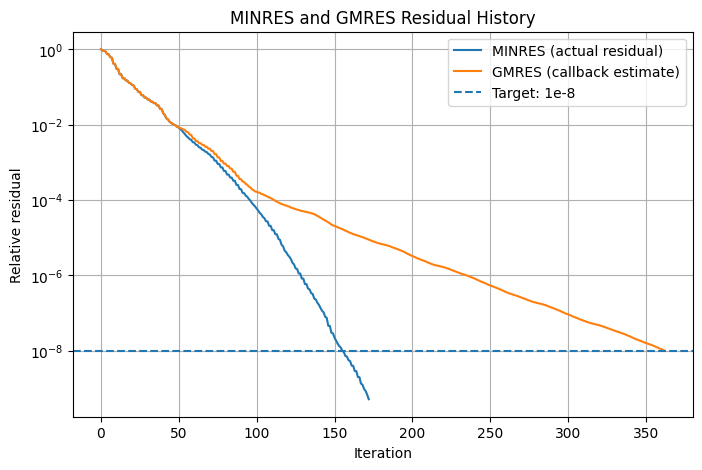

In [76]:
# Step 10: Plot residual convergence history

import matplotlib.pyplot as plt

# Use the largest mesh from Step 7
assert G_new.shape == (1312, 1312)

b_norm = np.linalg.norm(b_new)

# Store MINRES residuals
minres_history = []

def record_minres(x):
    residual = b_new - G_new @ x
    relative_residual = np.linalg.norm(residual) / b_norm
    minres_history.append(relative_residual)

# Run MINRES
z_m, info_m = minres(
    G_new, b_new,
    rtol=1e-12,
    maxiter=3000,
    callback=record_minres
)

# Store GMRES residual estimates
gmres_history = []

def record_gmres(value):
    gmres_history.append(value)

# Run GMRES
z_g, info_g = gmres(
    G_new, b_new,
    rtol=1e-8,
    atol=0.0,
    restart=50,
    maxiter=60,
    callback=record_gmres,
    callback_type="pr_norm"
)

# Calculate actual final relative residuals
final_minres = np.linalg.norm(b_new - G_new @ z_m) / b_norm
final_gmres = np.linalg.norm(b_new - G_new @ z_g) / b_norm

# Print results
print("MINRES info:", info_m)
print("MINRES iterations:", len(minres_history))
print("MINRES final relative residual:", final_minres)

print("GMRES info:", info_g)
print("GMRES iterations:", len(gmres_history))
print("GMRES final relative residual:", final_gmres)

# Plot residual histories
plt.figure(figsize=(8, 5))

plt.semilogy(minres_history, label="MINRES (actual residual)")
plt.semilogy(gmres_history, label="GMRES (callback estimate)")

plt.axhline(1e-8, linestyle="--", label="Target: 1e-8")

plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.title("MINRES and GMRES Residual History")
plt.legend()
plt.grid(True)

plt.show()

### Result

I plotted the residual history of MINRES and GMRES for the 16 × 16 mesh.

MINRES completed 173 iterations and gave a final relative residual of approximately 5.09 × 10⁻¹⁰.

GMRES completed 363 iterations and gave a final relative residual of approximately 9.93 × 10⁻⁹.

Both solvers reached my target relative residual of 10⁻⁸.

The graph shows that MINRES reduced the residual in fewer iterations than GMRES for this problem.

I used the actual relative residual for MINRES and the callback residual values for GMRES.

I can see how the residual changes during the iterations, but I still need to consider computation time before deciding which solver performs better.

This experiment helps me understand the convergence behavior of both methods.

## 11. Comparing Solver Times on the Larger Mesh

In this step, I will compare the computation times of the direct solver, MINRES, and GMRES on the 16 × 16 mesh.

The system has 1312 unknowns.

I will run each solver five times and calculate the average time in milliseconds.

For MINRES, I will use a requested tolerance of 10⁻¹². For GMRES, I will use 10⁻⁸.

I selected these settings because both solvers reached my actual relative residual target of 10⁻⁸ in the earlier tests.

I will check the residuals again and record the iteration counts.

This will help me compare the solver times on a larger system.


In [77]:
# Step 11: Compare solver times on the larger mesh

import time

# Use the 16 x 16 mesh from Step 7
assert G_new.shape == (1312, 1312)

# Store execution times
direct_times = []
minres_times = []
gmres_times = []

# Store iteration counts
minres_steps = []
gmres_steps = []

def count_minres(x):
    minres_steps.append(1)

def count_gmres(r):
    gmres_steps.append(1)

# Run each solver five times
for i in range(5):

    # Direct solver
    start = time.perf_counter()
    z_direct_large = spsolve(G_new, b_new)
    direct_times.append((time.perf_counter() - start) * 1000)

    # MINRES
    minres_steps.clear()

    start = time.perf_counter()
    z_minres_large, info_m = minres(
        G_new, b_new,
        rtol=1e-12,
        maxiter=3000,
        callback=count_minres
    )
    minres_times.append((time.perf_counter() - start) * 1000)

    # GMRES
    gmres_steps.clear()

    start = time.perf_counter()
    z_gmres_large, info_g = gmres(
        G_new, b_new,
        rtol=1e-8,
        atol=0.0,
        restart=50,
        maxiter=60,
        callback=count_gmres,
        callback_type="pr_norm"
    )
    gmres_times.append((time.perf_counter() - start) * 1000)

# Calculate average times
print("Direct solver average time (ms):", np.mean(direct_times))
print("MINRES average time (ms):", np.mean(minres_times))
print("GMRES average time (ms):", np.mean(gmres_times))

print("--------------------------------")

# Print iteration counts and solver status
print("MINRES iterations:", len(minres_steps))
print("GMRES iterations:", len(gmres_steps))
print("MINRES info:", info_m)
print("GMRES info:", info_g)

print("--------------------------------")

# Check actual relative residuals
b_norm = np.linalg.norm(b_new)

residual_m = np.linalg.norm(
    b_new - G_new @ z_minres_large
) / b_norm

residual_g = np.linalg.norm(
    b_new - G_new @ z_gmres_large
) / b_norm

print("MINRES relative residual:", residual_m)
print("GMRES relative residual:", residual_g)

print("MINRES meets target:", residual_m <= 1e-8)
print("GMRES meets target:", residual_g <= 1e-8)

Direct solver average time (ms): 4.591141999662796
MINRES average time (ms): 15.377134200207365
GMRES average time (ms): 176.45283000001655
--------------------------------
MINRES iterations: 173
GMRES iterations: 363
MINRES info: 0
GMRES info: 0
--------------------------------
MINRES relative residual: 5.088658758040113e-10
GMRES relative residual: 9.931933284838029e-09
MINRES meets target: True
GMRES meets target: True


### Result

I compared the computation times of the direct solver, MINRES, and GMRES on the 16 × 16 mesh.

The system had 1312 unknowns. I ran each solver five times and calculated the average execution time.

The direct solver took approximately 4.59 ms, MINRES took 15.38 ms, and GMRES took 176.45 ms.

These times may change when I run the notebook again.

MINRES converged in 173 iterations, while GMRES took 363 iterations.

Both iterative solvers reached my target relative residual of 10⁻⁸.

In this experiment, the direct solver was the fastest. MINRES also took much less time than GMRES.

However, I only tested one larger mesh and used five timing runs. The two iterative solvers also stopped at different final residual values.

I need more experiments before making a general conclusion about solver performance.

These results will be useful when I start studying preconditioners.

## 12. Final Summary of MINRES and GMRES Results

In this notebook, I tested MINRES and GMRES on a mixed Darcy saddle-point system.

I started with a small mesh and then tested larger meshes.

I checked the solver status, iteration counts, relative residuals, and computation times.

I also compared the iterative solutions with the direct solver.

In this step, I will collect the main results from the 16 × 16 mesh.

I will use these results as a reference when I start testing preconditioners.


In [78]:
# Step 12: Summary of solver results

print("MIXED DARCY - ITERATIVE SOLVER SUMMARY")
print("--------------------------------------")

# Problem information
print("Matrix shape:", G_new.shape)
print("Total unknowns:", G_new.shape[0])
print("Relative residual target:", 1e-8)

print("--------------------------------------")

# Average execution times
print("Direct solver time (ms):", np.mean(direct_times))
print("MINRES time (ms):", np.mean(minres_times))
print("GMRES time (ms):", np.mean(gmres_times))

print("--------------------------------------")

# Iteration counts
print("MINRES iterations:", len(minres_steps))
print("GMRES iterations:", len(gmres_steps))

# Solver status
print("MINRES info:", info_m)
print("GMRES info:", info_g)

print("--------------------------------------")

# Actual relative residuals
print("MINRES relative residual:", residual_m)
print("GMRES relative residual:", residual_g)

# Check target
print("MINRES meets target:", residual_m <= 1e-8)
print("GMRES meets target:", residual_g <= 1e-8)

MIXED DARCY - ITERATIVE SOLVER SUMMARY
--------------------------------------
Matrix shape: (1312, 1312)
Total unknowns: 1312
Relative residual target: 1e-08
--------------------------------------
Direct solver time (ms): 4.591141999662796
MINRES time (ms): 15.377134200207365
GMRES time (ms): 176.45283000001655
--------------------------------------
MINRES iterations: 173
GMRES iterations: 363
MINRES info: 0
GMRES info: 0
--------------------------------------
MINRES relative residual: 5.088658758040113e-10
GMRES relative residual: 9.931933284838029e-09
MINRES meets target: True
GMRES meets target: True


### Result

I collected the main results from my MINRES and GMRES experiments.

For the 16 × 16 mesh, the mixed Darcy system had 1312 unknowns.

The average execution times were approximately 4.59 ms for the direct solver, 15.38 ms for MINRES, and 176.45 ms for GMRES.

These times may change when I run the notebook again.

MINRES took 173 iterations, while GMRES took 363 iterations.

Both solvers returned `info = 0` and reached my actual relative residual target of 10⁻⁸.

In this experiment, the direct solver was the fastest, and MINRES took less time than GMRES.

These results are only for the current problem and solver settings. I will use them as a baseline when I start testing preconditioners.